In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import random

In [2]:
# Gaussian noise stream 1

fs = 2048          
duration = 1.0     # duration of each file in seconds
num_files = 100    # number of 1-second noise files

t_noise = np.arange(0, duration, 1/fs)
mu = 0.0           # mean of Gaussian noise
sigma = 1.0        # standard deviation of Gaussian noise
np.random.seed(29680801)
long_noise_stream1 = np.random.normal(mu, sigma, len(t_noise) * num_files)
noise_array_stream1 = []

i = 0
for n in range(num_files):
    noise = long_noise_stream1[i:i + len(t_noise)]
    noise_array_stream1.append(noise)
    i += len(t_noise)

noise_array_stream1 = np.array(noise_array_stream1)

# Print basic information
print("Shape of Stream 1 noise array:", noise_array_stream1.shape)
print("Number of files:", num_files)
print("Duration of each file:", duration, "s")

Shape of Stream 1 noise array: (100, 2048)
Number of files: 100
Duration of each file: 1.0 s


In [3]:
# Gaussian noise stream 2

fs = 2048          
duration = 1.0    
num_files = 100    

t_noise = np.arange(0, duration, 1/fs)
mu = 0.0           
sigma = 1.0        
np.random.seed(23982047)
long_noise_stream2 = np.random.normal(mu, sigma, len(t_noise) * num_files)
noise_array_stream2 = []

i = 0
for n in range(num_files):
    noise = long_noise_stream2[i:i + len(t_noise)]
    noise_array_stream2.append(noise)
    i += len(t_noise)

noise_array_stream2 = np.array(noise_array_stream2)
    
# Print basic information
print("Shape of Stream 2 noise array:", noise_array_stream2.shape)
print("Number of files:", num_files)
print("Duration of each file:", duration, "s")

Shape of Stream 2 noise array: (100, 2048)
Number of files: 100
Duration of each file: 1.0 s


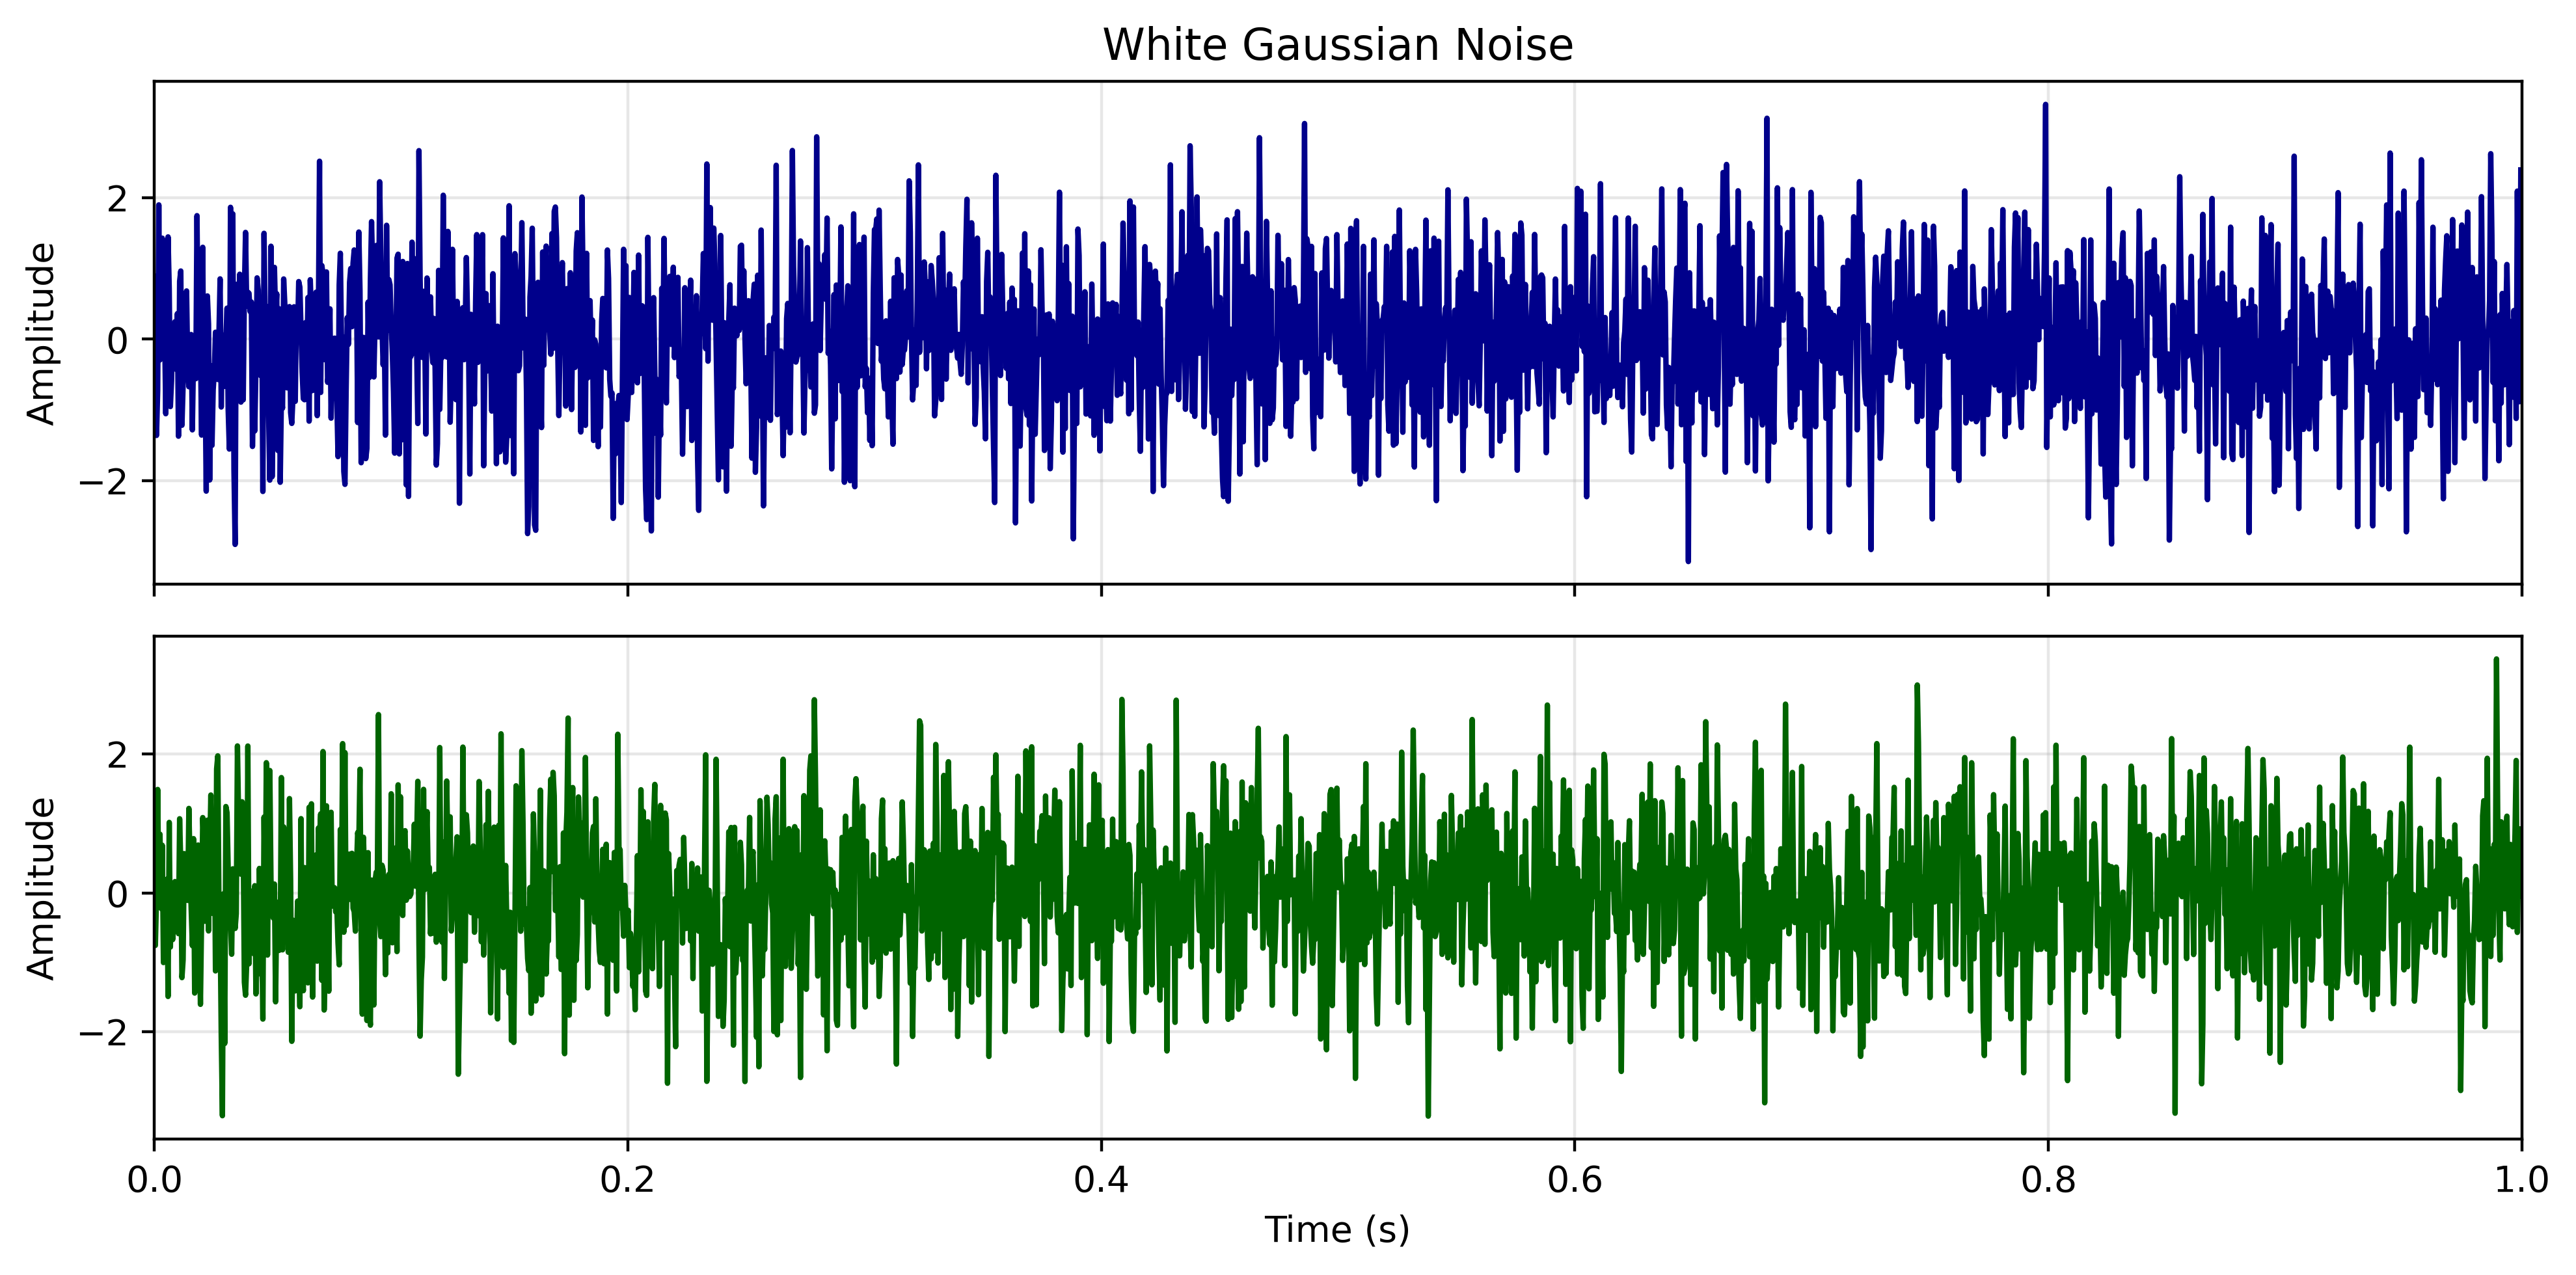

In [4]:
# Plot the first 1-second segment from both Gaussian-noise streams

segment_index = 0  # First 1-second segment

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5),
    dpi=400,
    sharex=True
)

# Stream 1
axes[0].plot(
    t_noise,
    noise_array_stream1[segment_index],
    color="darkblue",
    linewidth=1.5
)
axes[0].set_ylabel("Amplitude")
axes[0].set_title("White Gaussian Noise")
axes[0].grid(True, alpha=0.3)

# Stream 2
axes[1].plot(
    t_noise,
    noise_array_stream2[segment_index],
    color="darkgreen",
    linewidth=1.5
)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

# Both plots show exactly one second
axes[1].set_xlim(0, duration)

plt.tight_layout()

# Save before displaying
plt.savefig(
    "white_gaussian_noise_two_streams_1s.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [5]:
def cross_correlation(data1, data2, times):
    correlations = []
    lags = np.arange(-len(times)/2, len(times)/2, 1)
    nx = len(lags)
    nxs = np.arange(-nx//2, nx//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))

        correlation = sum(a * b for a, b in zip(data1_shifted, data2))
        correlation = correlation / len(times)

        correlations.append(correlation)

    return correlations, nxs

In [6]:
## Cross-correlation of noise-only streams for training

signals1 = []
signals2 = []

maxccs = []

fs = 2048
times = np.arange(0, 1, 1/fs)

for i in np.arange(0, num_files, 1):

    # Remove mean from both Gaussian noise streams
    noise1 = noise_array_stream1[i] - np.mean(noise_array_stream1[i])
    noise2 = noise_array_stream2[i] - np.mean(noise_array_stream2[i])

    # Split full 1-second noise streams into four sections
    noise1_sec1 = noise1[0:512]
    noise1_sec2 = noise1[512:1024]
    noise1_sec3 = noise1[1024:1536]
    noise1_sec4 = noise1[1536:2048]

    noise2_sec1 = noise2[0:512]
    noise2_sec2 = noise2[512:1024]
    noise2_sec3 = noise2[1024:1536]
    noise2_sec4 = noise2[1536:2048]

    # Cross-correlate noise-only sections
    ccnoise1 = cross_correlation(noise1_sec1, noise2_sec1, times[0:512])
    ccnoise2 = cross_correlation(noise1_sec2, noise2_sec2, times[512:1024])
    ccnoise3 = cross_correlation(noise1_sec3, noise2_sec3, times[1024:1536])
    ccnoise4 = cross_correlation(noise1_sec4, noise2_sec4, times[1536:2048])

    # Concatenate only noise cross-correlation streams
    final_sig = np.concatenate((ccnoise1[0],ccnoise2[0],ccnoise3[0],ccnoise4[0]))


    # save training files
    np.savetxt('../TranAD_MGB/data/SG_COR_LOWF_SNR10/train/' + str(i) + '_SG_COR_LOWF_SNR10_Anomaly_Gaussnoise_train.txt',final_sig)

    print('saved noise-only training file for:', i)

saved noise-only training file for: 0
saved noise-only training file for: 1
saved noise-only training file for: 2
saved noise-only training file for: 3
saved noise-only training file for: 4
saved noise-only training file for: 5
saved noise-only training file for: 6
saved noise-only training file for: 7
saved noise-only training file for: 8
saved noise-only training file for: 9
saved noise-only training file for: 10
saved noise-only training file for: 11
saved noise-only training file for: 12
saved noise-only training file for: 13
saved noise-only training file for: 14
saved noise-only training file for: 15
saved noise-only training file for: 16
saved noise-only training file for: 17
saved noise-only training file for: 18
saved noise-only training file for: 19
saved noise-only training file for: 20
saved noise-only training file for: 21
saved noise-only training file for: 22
saved noise-only training file for: 23
saved noise-only training file for: 24
saved noise-only training file for:

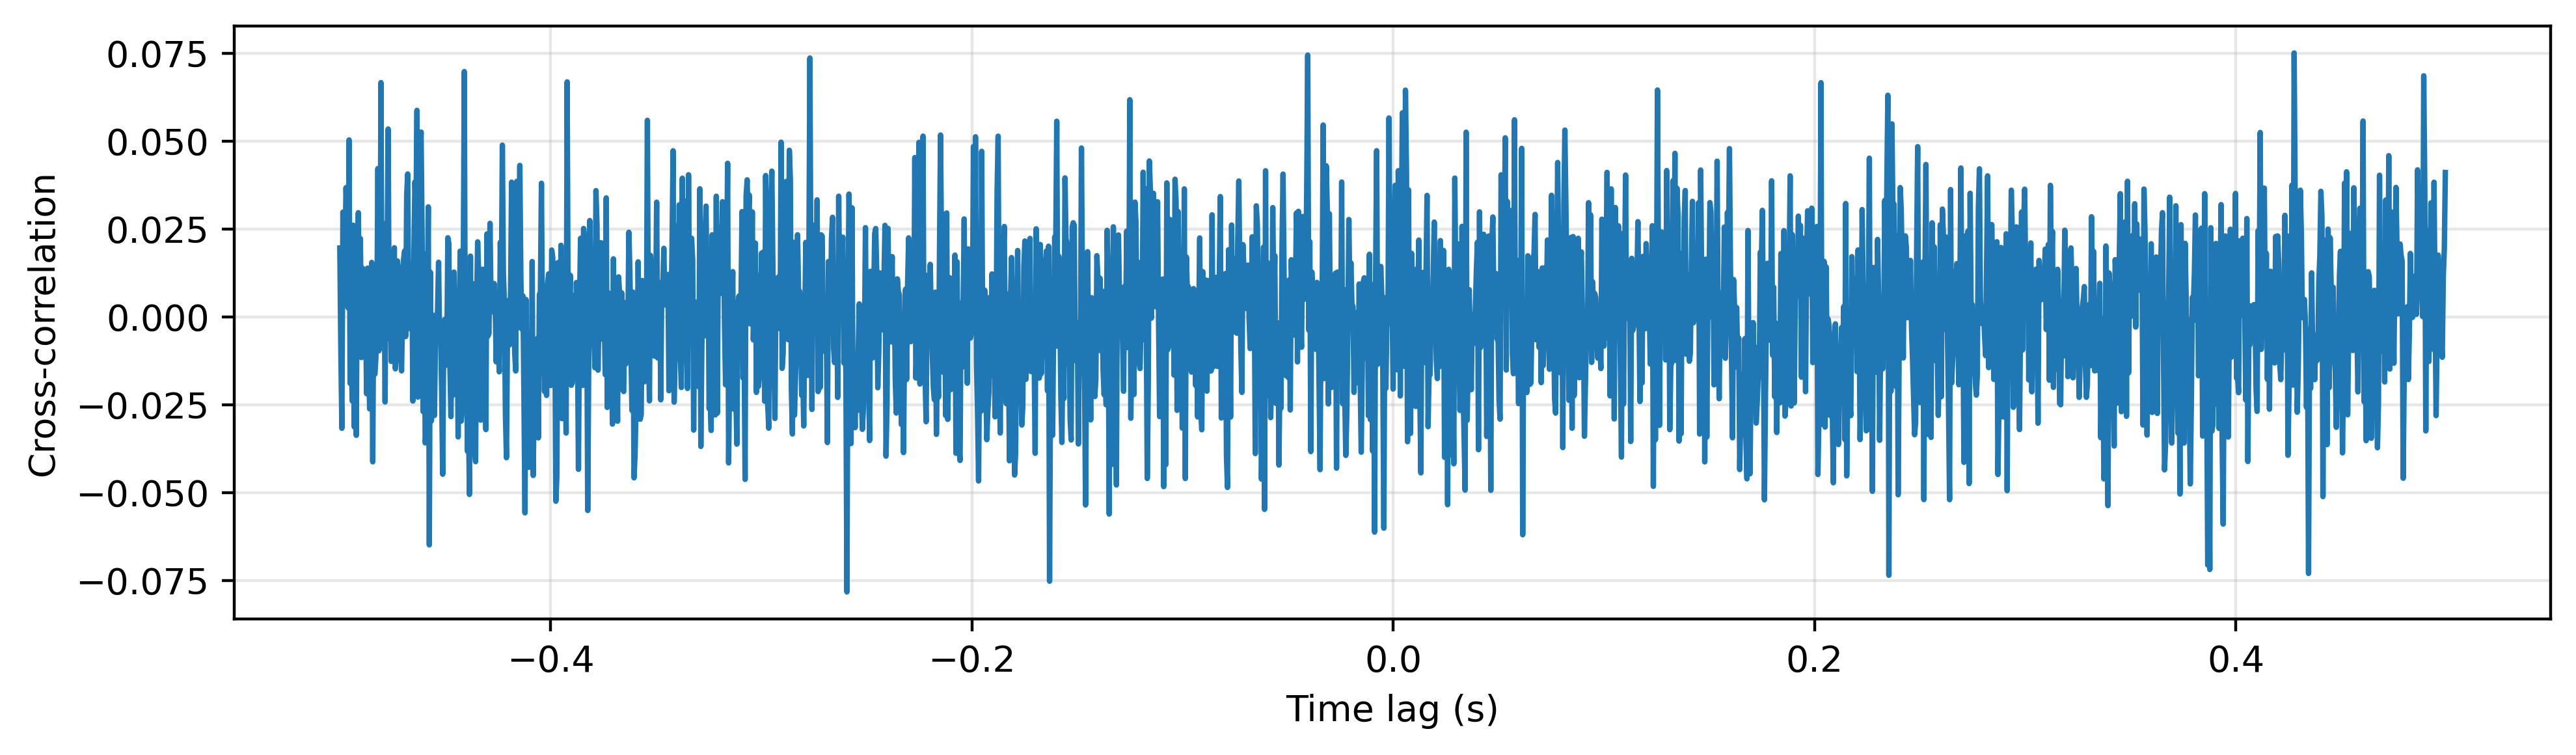

In [7]:
# Cross-correlation of one H1-L1 segment
correlations, lag_samples = cross_correlation(noise1, noise2, times)

lag_samples = np.asarray(lag_samples)
lag_seconds = lag_samples / fs

plt.figure(figsize=(10, 3), dpi=400)

plt.plot(lag_seconds, correlations, linewidth=1.5)

plt.xlabel("Time lag (s)")
plt.ylabel("Cross-correlation")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("cross_correlation_lag.png", dpi=400, bbox_inches="tight")
plt.show()